In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving superstore.csv to superstore.csv


In [2]:
df = pd.read_csv('superstore.csv')

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (9800, 18)

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680



Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region   

In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique orders and customers
print("\nUnique Orders:", df['Order ID'].nunique())
print("Unique Customers:", df['Customer ID'].nunique())

# Check total sales
print("\nTotal Sales:", round(df['Sales'].sum(), 2))

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

Duplicate Rows: 0

Unique Orders: 4922
Unique Customers: 793

Total Sales: 2261536.78


In [4]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%d-%m-%Y'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='%d-%m-%Y'
)

print(df[['Order Date', 'Ship Date']].dtypes)

print("\nDate Range:")
print("First Order:", df['Order Date'].min())
print("Last Order:", df['Order Date'].max())

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

Date Range:
First Order: 2015-01-03 00:00:00
Last Order: 2018-12-30 00:00:00


Month Name
January       94291.63
February      59371.12
March        197573.59
April        136283.00
May          154086.72
June         145837.52
July         145535.69
August       157315.93
September    300103.41
October      199496.29
November     350161.71
December     321480.17
Name: Sales, dtype: float64


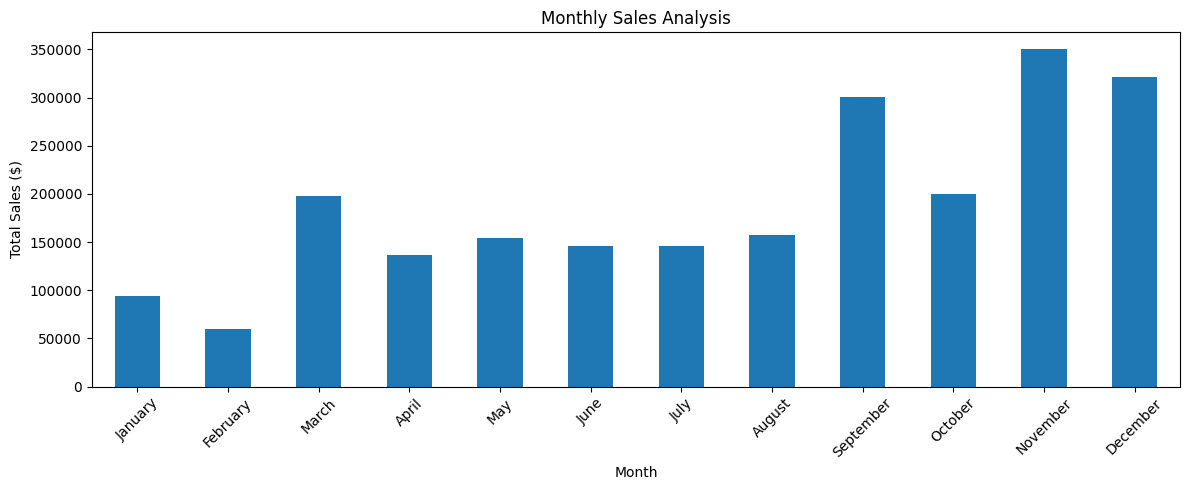

In [5]:
# Extract year and month
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()

# Monthly sales
monthly_sales = (
    df.groupby('Month Name')['Sales']
    .sum()
    .reindex([
        'January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December'
    ])
)

print(monthly_sales.round(2))

# Visualisation
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='bar')
plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Yearly Sales:
Year
2015    479856.21
2016    459436.01
2017    600192.55
2018    722052.02
Name: Sales, dtype: float64


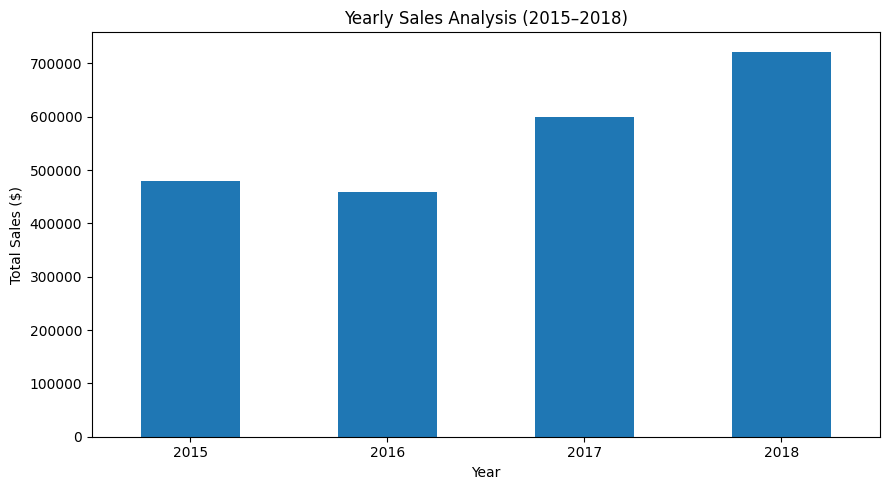

In [6]:
yearly_sales = df.groupby('Year')['Sales'].sum()

print("Yearly Sales:")
print(yearly_sales.round(2))

# Visualisation
plt.figure(figsize=(9, 5))
yearly_sales.plot(kind='bar')

plt.title('Yearly Sales Analysis (2015–2018)')
plt.xlabel('Year')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Set analysis date
snapshot_date = df['Order Date'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = df.groupby('Customer ID').agg(
    Recency=('Order Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum')
)

print("RFM Analysis:")
display(rfm.head(10))

print("\nTotal Customers:", len(rfm))

RFM Analysis:


,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
AB-10060,55,8,7755.620
AB-10105,42,10,14473.571
AB-10150,42,5,966.710
AB-10165,26,8,1113.838



Total Customers: 793


In [8]:
# Assign RFM scores (1 to 4)
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

# Calculate combined score
rfm['RFM_Score'] = (
    rfm['R_Score'] +
    rfm['F_Score'] +
    rfm['M_Score']
)

# Create customer segments
def segment_customer(row):
    if row['RFM_Score'] >= 10:
        return 'High Value'
    elif row['RFM_Score'] >= 7:
        return 'Regular'
    elif row['RFM_Score'] >= 5:
        return 'At Risk'
    else:
        return 'Low Value'

rfm['Customer Segment'] = rfm.apply(
    segment_customer, axis=1
)

# Segment summary
segment_summary = rfm.groupby('Customer Segment').agg(
    Customers=('Recency', 'count'),
    Total_Spending=('Monetary', 'sum')
)

display(segment_summary)

,Customers,Total_Spending
Customer Segment,,
At Risk,178,256912.6150
High Value,201,944677.6268
Low Value,116,88556.7205
Regular,298,971389.8204


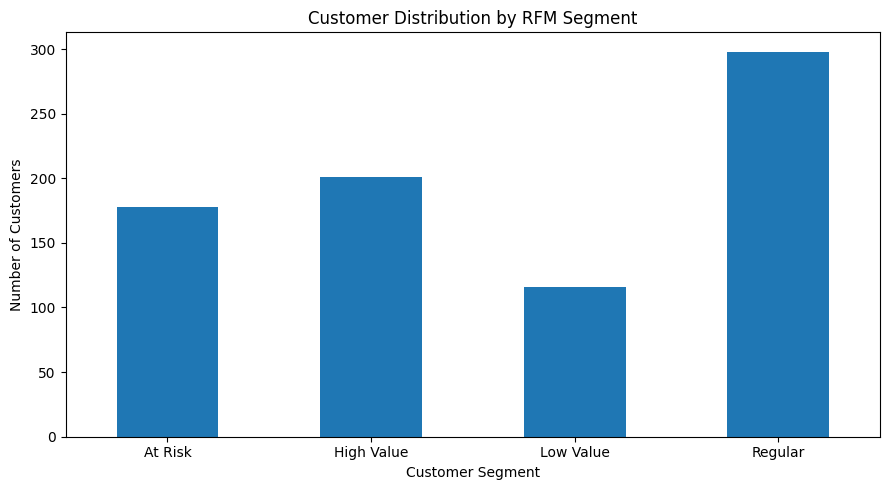

In [9]:
plt.figure(figsize=(9, 5))

segment_summary['Customers'].plot(
    kind='bar'
)

plt.title('Customer Distribution by RFM Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Prepare yearly sales data
forecast_data = df.groupby('Year')['Sales'].sum().reset_index()

forecast_data.columns = ['Year', 'Sales']

display(forecast_data)

,Year,Sales
0,2015,479856.2081
1,2016,459436.0054
2,2017,600192.5500
3,2018,722052.0192


In [11]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Prepare data
X = forecast_data[['Year']]
y = forecast_data['Sales']

# Train model
model = LinearRegression()
model.fit(X, y)

# Predict sales for 2019 and 2020
future_years = pd.DataFrame({'Year': [2019, 2020]})
predictions = model.predict(future_years)

forecast_data_future = future_years.copy()
forecast_data_future['Forecasted Sales'] = predictions

display(forecast_data_future.round(2))

,Year,Forecasted Sales
0,2019,782220.19
1,2020,868954.59


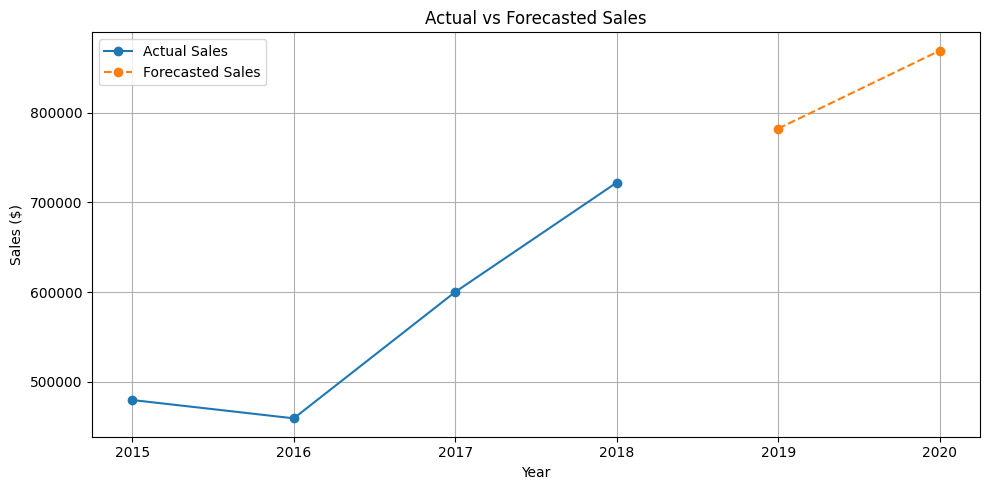

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    forecast_data['Year'],
    forecast_data['Sales'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    forecast_data_future['Year'],
    forecast_data_future['Forecasted Sales'],
    marker='o',
    linestyle='--',
    label='Forecasted Sales'
)

plt.title('Actual vs Forecasted Sales')
plt.xlabel('Year')
plt.ylabel('Sales ($)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()